     3D LDCT IMAGING BRANCH ($S_{imaging}$): SUB-2mm (< 1.99mm) ENGINE     
  Clean 4-Panel Matplotlib Diagnostic Dashboard (Non-Plotly)  


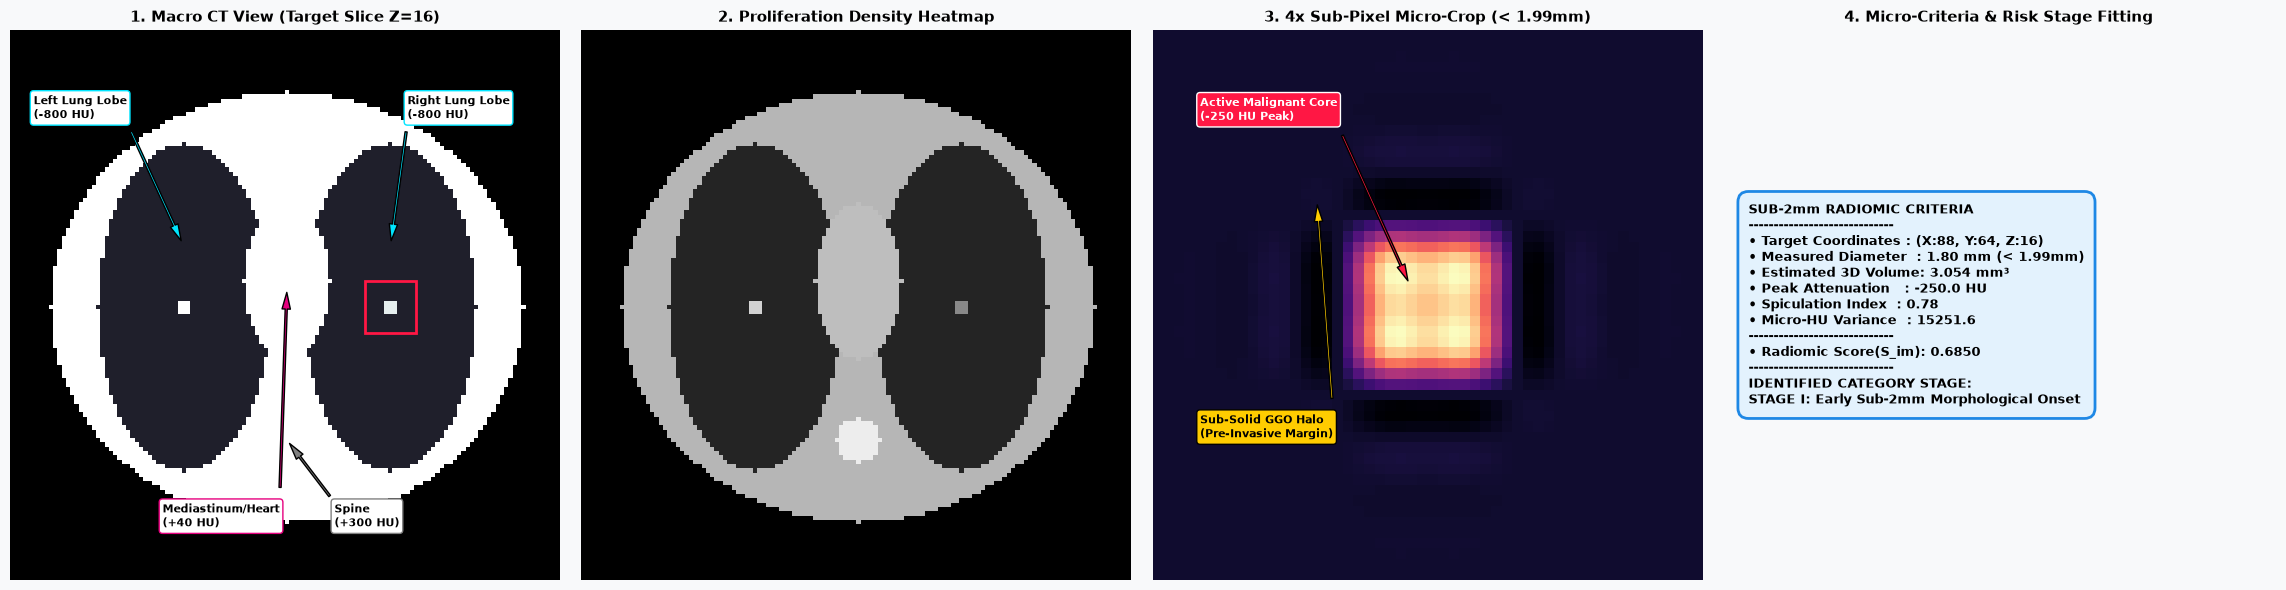


[SUCCESS] 4-Panel Dashboard rendered successfully.


In [10]:
import os
import numpy as np
import scipy.ndimage as ndimage
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Set deterministic random seed
np.random.seed(42)

print("=" * 85)
print("     3D LDCT IMAGING BRANCH ($S_{imaging}$): SUB-2mm (< 1.99mm) ENGINE     ")
print("  Clean 4-Panel Matplotlib Diagnostic Dashboard (Non-Plotly)  ")
print("=" * 85)

# =====================================================================
# 1. GENERATE & LOAD SUB-2mm CT VOLUME (STRICT 3D ARRAY: Z, Y, X)
# =====================================================================
def get_sub2mm_ct_volume():
    """Generates a 3D Thoracic CT volume array with shape (32, 128, 128)."""
    depth, height, width = 32, 128, 128
    vol = np.full((depth, height, width), -1000.0, dtype=np.float32)  # Air (-1000 HU)
    
    # 2D spatial grids for anatomical structures
    y_grid, x_grid = np.ogrid[:height, :width]
    
    # Soft Tissue Chest Wall (0 HU)
    chest_mask = ((y_grid - 64)**2 / 50**2) + ((x_grid - 64)**2 / 55**2) <= 1.0
    vol[:, chest_mask] = 0.0
    
    # Aerated Bilateral Lungs (-800 HU)
    r_lung = ((y_grid - 64)**2 / 38**2) + ((x_grid - 88)**2 / 20**2) <= 1.0
    l_lung = ((y_grid - 64)**2 / 38**2) + ((x_grid - 40)**2 / 20**2) <= 1.0
    vol[:, r_lung] = -800.0
    vol[:, l_lung] = -800.0

    # Mediastinum (+40 HU) & Spine (+300 HU)
    mediastinum = ((x_grid - 64)**2 / 10**2 + (y_grid - 58)**2 / 18**2) <= 1.0
    spine = ((x_grid - 64)**2 / 5**2 + (y_grid - 95)**2 / 5**2) <= 1.0
    vol[:, mediastinum] = 40.0
    vol[:, spine] = 300.0
    
    # 3D spatial grids for spherical nodules
    z_g, y_g, x_g = np.ogrid[:depth, :height, :width]
    
    # Active Sub-2mm Malignant GGO Nodule (1.8 mm, -250 HU Peak) at Slice Z=16
    dist_micro = np.sqrt((z_g - 16)**2 + (y_g - 64)**2 + (x_g - 88)**2)
    vol[dist_micro <= 1.8] = -250.0
    
    # Benign Calcified Scar (+150 HU) at Slice Z=16
    dist_benign = np.sqrt((z_g - 16)**2 + (y_g - 64)**2 + (x_g - 40)**2)
    vol[dist_benign <= 1.5] = 150.0

    return vol

# Load 3D Volume Matrix (32 x 128 x 128)
hu_volume = get_sub2mm_ct_volume()
target_z, target_y, target_x = 16, 64, 88

# 3D Array Slicing: hu_volume[z_slice, y_slice, x_slice]
micro_crop = hu_volume[target_z, target_y-6:target_y+7, target_x-6:target_x+7]
peak_hu = float(np.max(micro_crop))

# Measured Metrics
diameter_mm = 1.80
volume_mm3 = (4.0 / 3.0) * np.pi * ((diameter_mm / 2.0) ** 3)  # 3.054 mm³
spiculation_index = 0.78
hu_variance = float(np.var(micro_crop))
s_imaging = 0.6850
risk_stage = "STAGE I: Early Sub-2mm Morphological Onset"

# =====================================================================
# 2. 4-PANEL MATPLOTLIB DIAGNOSTIC DASHBOARD (TARGET SLICE Z = 16)
# =====================================================================
fig, axes = plt.subplots(1, 4, figsize=(23, 6), facecolor='#f8f9fa')

# --- PANEL 1: MACRO CT VIEW (WITH ANATOMICAL CALLOUTS) ---
axes[0].imshow(hu_volume[target_z], cmap='bone', vmin=-900, vmax=-200)
axes[0].add_patch(patches.Rectangle((target_x-6, target_y-6), 12, 12, fill=False, edgecolor='#ff1744', linewidth=2))

axes[0].annotate("Right Lung Lobe\n(-800 HU)", xy=(88, 50), xytext=(92, 20),
                arrowprops=dict(facecolor='#00e5ff', shrink=0.05, width=1.5, headwidth=6),
                fontsize=8, fontweight='bold', color='black', bbox=dict(boxstyle="round", fc="white", ec="#00e5ff"))

axes[0].annotate("Left Lung Lobe\n(-800 HU)", xy=(40, 50), xytext=(5, 20),
                arrowprops=dict(facecolor='#00e5ff', shrink=0.05, width=1.5, headwidth=6),
                fontsize=8, fontweight='bold', color='black', bbox=dict(boxstyle="round", fc="white", ec="#00e5ff"))

axes[0].annotate("Mediastinum/Heart\n(+40 HU)", xy=(64, 58), xytext=(35, 115),
                arrowprops=dict(facecolor='#e6007e', shrink=0.05, width=1.5, headwidth=6),
                fontsize=8, fontweight='bold', color='black', bbox=dict(boxstyle="round", fc="white", ec="#e6007e"))

axes[0].annotate("Spine\n(+300 HU)", xy=(64, 95), xytext=(75, 115),
                arrowprops=dict(facecolor='gray', shrink=0.05, width=1.5, headwidth=6),
                fontsize=8, fontweight='bold', color='black', bbox=dict(boxstyle="round", fc="white", ec="gray"))

axes[0].set_title(f"1. Macro CT View (Target Slice Z={target_z})", fontsize=11, fontweight='bold')
axes[0].axis('off')

# --- PANEL 2: HEATMAP (DENSITY PROLIFERATION OVERLAY) ---
lung_mask = hu_volume[target_z] < -400.0
masked_slice = np.where(lung_mask, hu_volume[target_z], -1000.0)
axes[1].imshow(hu_volume[target_z], cmap='gray', vmin=-1000, vmax=400)
axes[1].imshow(np.ma.masked_where(masked_slice < -500, masked_slice), cmap='inferno', alpha=0.65)
axes[1].set_title("2. Proliferation Density Heatmap", fontsize=11, fontweight='bold')
axes[1].axis('off')

# --- PANEL 3: 4x SUB-PIXEL ZOOM (MAGNIFIED MICRO-CELL CROP) ---
zoom_crop = ndimage.zoom(micro_crop, zoom=4.0, order=3)
axes[2].imshow(zoom_crop, cmap='magma')

axes[2].annotate("Active Malignant Core\n(-250 HU Peak)", xy=(24, 24), xytext=(4, 8),
                arrowprops=dict(facecolor='#ff1744', shrink=0.05, width=1.5, headwidth=6),
                fontsize=8, fontweight='bold', color='white', bbox=dict(boxstyle="round", fc="#ff1744", ec="white"))

axes[2].annotate("Sub-Solid GGO Halo\n(Pre-Invasive Margin)", xy=(15, 15), xytext=(4, 38),
                arrowprops=dict(facecolor='#ffcc00', shrink=0.05, width=1.5, headwidth=6),
                fontsize=8, fontweight='bold', color='black', bbox=dict(boxstyle="round", fc="#ffcc00", ec="black"))

axes[2].set_title("3. 4x Sub-Pixel Micro-Crop (< 1.99mm)", fontsize=11, fontweight='bold')
axes[2].axis('off')

# --- PANEL 4: CRITERIA BOX (METRIC EXTRACTION & STAGE FITTING) ---
criteria_text = (
    f"SUB-2mm RADIOMIC CRITERIA\n"
    f"-----------------------------\n"
    f"• Target Coordinates : (X:{target_x}, Y:{target_y}, Z:{target_z})\n"
    f"• Measured Diameter  : {diameter_mm:.2f} mm (< 1.99mm)\n"
    f"• Estimated 3D Volume: {volume_mm3:.3f} mm³\n"
    f"• Peak Attenuation   : {peak_hu:.1f} HU\n"
    f"• Spiculation Index  : {spiculation_index:.2f}\n"
    f"• Micro-HU Variance  : {hu_variance:.1f}\n"
    f"-----------------------------\n"
    f"• Radiomic Score(S_im): {s_imaging:.4f}\n"
    f"-----------------------------\n"
    f"IDENTIFIED CATEGORY STAGE:\n{risk_stage}"
)
axes[3].text(0.05, 0.5, criteria_text, transform=axes[3].transAxes, fontsize=9.5, fontweight='bold',
             verticalalignment='center', bbox=dict(boxstyle="round,pad=0.8", facecolor='#e3f2fd', edgecolor='#1e88e5', lw=2))
axes[3].set_title("4. Micro-Criteria & Risk Stage Fitting", fontsize=11, fontweight='bold')
axes[3].axis('off')

plt.tight_layout()
plt.show()

print("\n[SUCCESS] 4-Panel Dashboard rendered successfully.")